In [1]:
import requests
import json

weather_url = "https://api.open-meteo.com/v1/forecast"
weather_params = {
    "latitude": 31.5497,
    "longitude": 74.3436,
    "hourly": "temperature_2m,relative_humidity_2m",
    "timezone": "Asia/Karachi",
}

r = requests.get(weather_url, params=weather_params)
print("Status:", r.status_code)

data = r.json()
print(data.keys())
print(json.dumps(data, indent=2)[:1500])


Status: 200
dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])
{
  "latitude": 31.528997,
  "longitude": 74.38995,
  "generationtime_ms": 0.058770179748535156,
  "utc_offset_seconds": 18000,
  "timezone": "Asia/Karachi",
  "timezone_abbreviation": "GMT+5",
  "elevation": 222.0,
  "hourly_units": {
    "time": "iso8601",
    "temperature_2m": "\u00b0C",
    "relative_humidity_2m": "%"
  },
  "hourly": {
    "time": [
      "2026-10-31T00:00",
      "2026-10-31T01:00",
      "2026-10-31T02:00",
      "2026-10-31T03:00",
      "2026-10-31T04:00",
      "2026-10-31T05:00",
      "2026-10-31T06:00",
      "2026-10-31T07:00",
      "2026-10-31T08:00",
      "2026-10-31T09:00",
      "2026-10-31T10:00",
      "2026-10-31T11:00",
      "2026-10-31T12:00",
      "2026-10-31T13:00",
      "2026-10-31T14:00",
      "2026-10-31T15:00",
      "2026-10-31T16:00",
      "2026-10-31T17:00",
      "

In [2]:
print(data["hourly"].keys())
print(data["hourly"]["time"][0])
print(data["hourly"]["temperature_2m"][0])


dict_keys(['time', 'temperature_2m', 'relative_humidity_2m'])
2026-10-31T00:00
21.1


In [3]:

print(data["hourly"]["time"][1])
print(data["hourly"]["temperature_2m"][1])
print(len(data["hourly"]["time"]))


2026-10-31T01:00
20.7
168


In [4]:
import pandas as pd

df = pd.DataFrame(data["hourly"])
print(df.head())
print(df.shape)


               time  temperature_2m  relative_humidity_2m
0  2026-10-31T00:00            21.1                    80
1  2026-10-31T01:00            20.7                    81
2  2026-10-31T02:00            20.1                    83
3  2026-10-31T03:00            19.9                    83
4  2026-10-31T04:00            19.3                    85
(168, 3)


In [5]:
df["time"] = pd.to_datetime(df["time"])
print(df.dtypes)
print(df["temperature_2m"].max(), df["temperature_2m"].min())

time                    datetime64[ns]
temperature_2m                 float64
relative_humidity_2m             int64
dtype: object
29.1 17.5


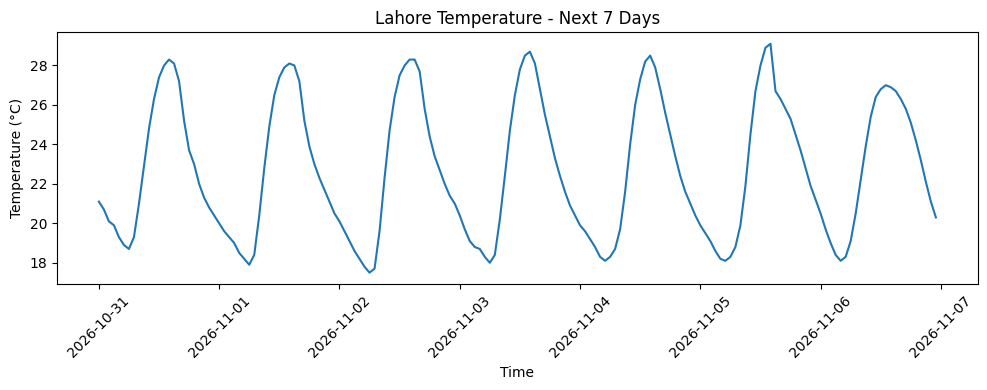

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(df["time"], df["temperature_2m"])
plt.title("Lahore Temperature - Next 7 Days")
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()